<a href="https://colab.research.google.com/github/jberisso/BA305-A1---hotel-bookings/blob/main/01_Descriptive.Question.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

Do bookings at City Hotels and Resort Hotels have distinct profiles based on lead time, price, party size, and special requests, or are they more similar when these characteristics are considered together?

To answer this question, we analyzed five numerical variables capturing financial behavior and booking characteristics. We wanted to determine whether the two hotel types attract different booking profiles or share similar characteristics despite being different property types. These findings could help managers determine whether shared pricing and marketing strategies are appropriate or whether each property requires a different approach.

In [2]:
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


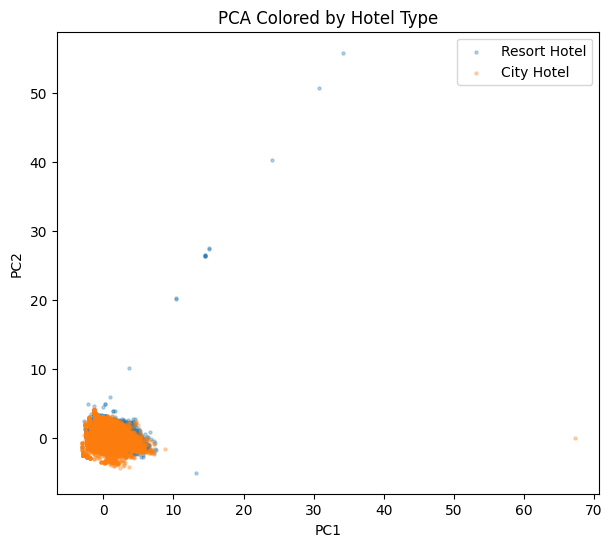

Explained variance ratio: [0.30273916 0.22357076]


In [3]:
features = ['lead_time', 'adr', 'adults', 'children', 'total_of_special_requests']
pca_data = df[features].fillna(0)

scaled = StandardScaler().fit_transform(pca_data)

pca = PCA(n_components=2)
pcs = pca.fit_transform(scaled)

plt.figure(figsize=(7, 6))
for h in df['hotel'].unique():
    mask = df['hotel'] == h
    plt.scatter(pcs[mask, 0], pcs[mask, 1], label=h, alpha=0.3, s=5)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend()
plt.title('PCA Colored by Hotel Type')
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)

We started by selecting five numerical variables to describe booking behavior: lead time, average daily rate (ADR), number of adults, number of children, and number of special requests. We chose these variables because they capture both financial behavior and travel-planning characteristics.

We then standardized the five variables using StandardScaler because PCA is sensitive to differences in scale. This ensured that variables such as ADR, which can reach hundreds of dollars, would not disproportionately influence the analysis compared to variables such as the number of children.

We applied PCA to reduce the five numerical variables into two principal components (PC1 and PC2), which together explained 52.6% of the total variance. We then created a scatterplot colored by hotel type to visualize whether City and Resort Hotel bookings formed distinct profiles or substantially overlapped.

In [4]:
pca_df = pd.DataFrame(pcs, columns=['PC1', 'PC2'], index=pca_data.index)
outliers = pca_df.sort_values('PC1', ascending=False).head(10)
df.loc[outliers.index, features + ['hotel', 'is_canceled']]

,lead_time,adr,adults,children,total_of_special_requests,hotel,is_canceled
48515,35,5400.0,2,0.0,0,City Hotel,1
2173,338,0.0,55,0.0,0,Resort Hotel,1
1643,336,0.0,50,0.0,0,Resort Hotel,1
1539,304,0.0,40,0.0,0,Resort Hotel,1
1917,349,0.0,27,0.0,0,Resort Hotel,1
1962,352,0.0,27,0.0,0,Resort Hotel,1
1587,333,0.0,26,0.0,0,Resort Hotel,1
1752,340,0.0,26,0.0,0,Resort Hotel,1
1884,347,0.0,26,0.0,0,Resort Hotel,1
2003,354,0.0,26,0.0,0,Resort Hotel,1


We sorted the observations by PC1 and examined the ten bookings with the most extreme values. We identified several unusual observations, including one booking with an ADR of 5,400 dollars and multiple Resort Hotel bookings with lead times exceeding 300 days, an ADR of exactly $0.00, and unusually high adult counts ranging from 26 to 55 on a single reservation.

In [10]:
features = ['lead_time', 'adr', 'adults', 'children', 'total_of_special_requests']
df.groupby('hotel')[features].agg(['mean', 'median', 'std']).round(2)

lead_time                    adr               adults         \
                  mean median     std    mean median    std   mean median   
hotel                                                                       
City Hotel      109.74   74.0  110.95  105.30   99.9  43.60   1.85    2.0   
Resort Hotel     92.68   57.0   97.29   94.95   75.0  61.44   1.87    2.0   

                   children              total_of_special_requests         \
               std     mean median   std                      mean median   
hotel                                                                       
City Hotel    0.51     0.09    0.0  0.37                      0.55    0.0   
Resort Hotel  0.70     0.13    0.0  0.45                      0.62    0.0   

                    
               std  
hotel               
City Hotel    0.78  
Resort Hotel  0.81

We used a groupby operation to compare the mean, median, and standard deviation of the five numerical variables across hotel types. We found that City Hotel bookings had longer lead times (109.7 vs. 92.7 days) and higher average daily rates ($105.30 vs. $94.95). However, both hotel types were similar in party size and number of special requests.

The standard deviations are large relative to these gaps in the means. For example, lead time varies by about 110.9 days within City Hotel bookings and 97.3 days within Resort Hotel bookings, while the difference between the two hotels’ average lead times is only 17 days. This means the two hotels’ distributions overlap heavily even where their averages differ.

Overall, the main differences were in pricing and booking timing rather than guest composition. The next step checks whether these differences translate into distinct booking profiles when all five characteristics are considered together.

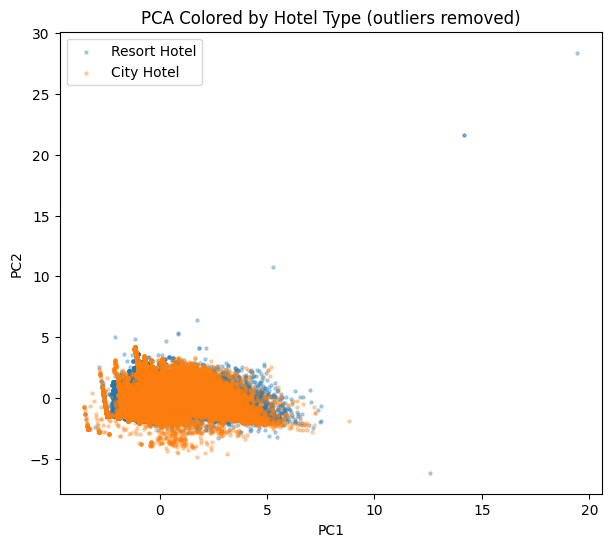

Explained variance ratio (outliers removed): [0.31415513 0.22390533]


In [6]:
clean_data = df.drop(index=outliers.index)
pca_data_clean = clean_data[features].fillna(0)
scaled_clean = StandardScaler().fit_transform(pca_data_clean)

pca_clean = PCA(n_components=2)
pcs_clean = pca_clean.fit_transform(scaled_clean)

plt.figure(figsize=(7, 6))
for h in clean_data['hotel'].unique():
    mask = clean_data['hotel'] == h
    plt.scatter(pcs_clean[mask, 0], pcs_clean[mask, 1], label=h, alpha=0.3, s=5)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend()
plt.title('PCA Colored by Hotel Type (outliers removed)')
plt.show()

print("Explained variance ratio (outliers removed):", pca_clean.explained_variance_ratio_)

After removing the ten flagged outliers, we standardized the variables again and reran PCA. The first two principal components explained approximately 53.8% of the total variance (31.4% and 22.4%). Since this was only a small change from the original 52.6%, we concluded that the identified outliers did not substantially affect the overall PCA structure.

Next, we examined the PCA component loadings to understand which variables contributed most to each component.

In [7]:
components_df = pd.DataFrame(
    pca_clean.components_,
    columns=features,
    index=['PC1', 'PC2']
)
print(components_df.round(3))

# Which single feature contributes most to each component?
for pc in components_df.index:
    top_feature = components_df.loc[pc].abs().idxmax()
    print(f'{pc} is most driven by: {top_feature} (loading = {components_df.loc[pc, top_feature]:.3f})')

     lead_time    adr  adults  children  total_of_special_requests
PC1     -0.072  0.644   0.443     0.475                      0.398
PC2      0.790 -0.017   0.544    -0.236                     -0.155
PC1 is most driven by: adr (loading = 0.644)
PC2 is most driven by: lead_time (loading = 0.790)


PC1 has positive loadings on ADR (0.644), children (0.475), adults (0.443), and special requests (0.398), so it represents overall booking size and spend: larger parties that pay more and make more requests. PC2 is driven mainly by lead time (0.790) and adults (0.544), so it represents bookings for larger groups made far in advance.

This helps us interpret the PCA visualization: differences between City and Resort Hotel bookings would appear as one hotel sitting further along the spend/size axis (PC1) or the advance-planning axis (PC2).

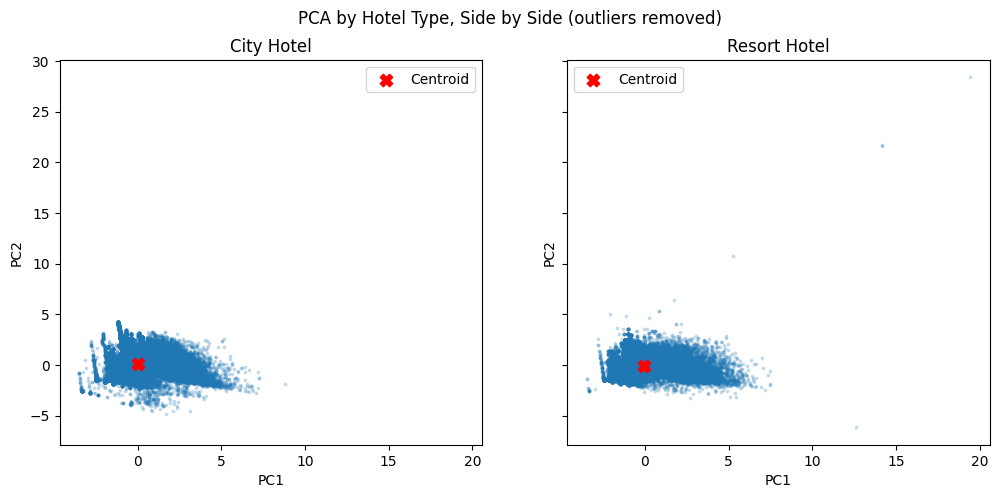

PC1         PC2      
              mean   std  mean   std
hotel                               
City Hotel    0.01  1.15  0.05  1.09
Resort Hotel -0.02  1.44 -0.10  0.98

In [11]:
pc_df = pd.DataFrame(pcs_clean, columns=['PC1', 'PC2'], index=clean_data.index)
pc_df['hotel'] = clean_data['hotel']

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, h in zip(axes, ['City Hotel', 'Resort Hotel']):
    sub = pc_df[pc_df['hotel'] == h]
    ax.scatter(sub['PC1'], sub['PC2'], s=3, alpha=0.2)
    ax.scatter(sub['PC1'].mean(), sub['PC2'].mean(), color='red', s=80, marker='X', label='Centroid')
    ax.set_title(h); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend()
plt.suptitle('PCA by Hotel Type, Side by Side (outliers removed)')
plt.show()

pc_df.groupby('hotel')[['PC1', 'PC2']].agg(['mean', 'std']).round(2)

In the combined scatterplot, City Hotel points were drawn on top of Resort Hotel points, which hid the overlap. Plotting each hotel in its own panel on the same axes shows that both occupy nearly the same region. The centroids (red X) are only 0.03 apart on PC1 (0.01 vs. –0.02) and 0.15 apart on PC2 (0.05 vs. –0.10), which is very small compared with the standard deviations of roughly 1.0 to 1.4 within each hotel. In other words, the gap between the two hotels’ average bookings is about one-tenth of the variation among bookings at the same hotel. Resort Hotel bookings are somewhat more spread out along PC1 (std 1.44 vs. 1.15), including a few extreme points, but the core of both distributions is the same.

In [12]:
s = silhouette_score(scaled_clean, clean_data['hotel'], sample_size=5000, random_state=42)
print(f"Silhouette score by hotel type: {s:.3f}")

Silhouette score by hotel type: 0.031


Through this analysis, we found that City Hotel bookings tend to have higher daily rates and longer lead times than Resort Hotel bookings, while guest composition and special requests remain relatively similar. Our PCA analysis provided an additional perspective by allowing us to examine these characteristics together rather than individually. We also identified unusual canceled bookings that highlighted potential data-quality issues.

Together, these findings help us assess whether City and Resort Hotels attract distinct booking profiles or share similar characteristics, providing useful information for managers when considering whether pricing and marketing strategies should be shared or tailored to each property.